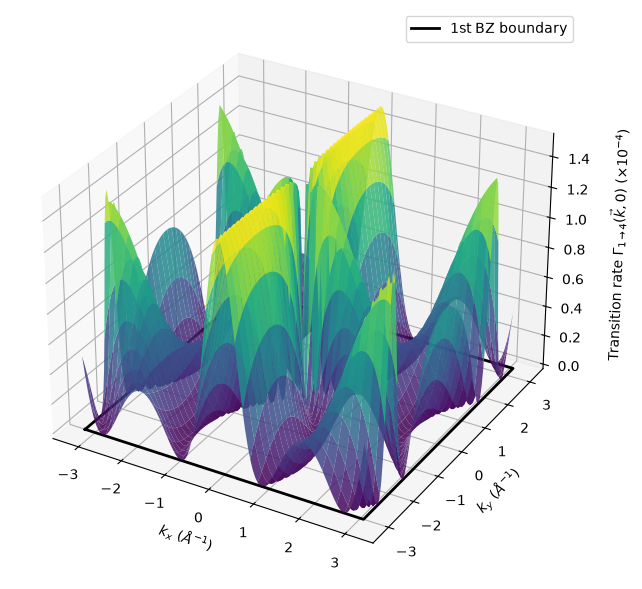

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from scipy import constants

# Constants
a = 1
t = 1
h = constants.hbar
E_o = 1
omega = 3*t/h
pi = np.pi
e = constants.elementary_charge

# Vectors
es = np.array([[np.sqrt(3)/2, 1/2], [-np.sqrt(3)/2, 1/2], [0,-1]])
deltas = a*es, 
Deltas = np.array([[-np.sqrt(3)/2, 3/2], [-np.sqrt(3)/2, -3/2], [np.sqrt(3), 0]])
bs = (2*pi/3*a)*np.array([[np.sqrt(3), 1], [-np.sqrt(3), 1]])

# Functions
def f_i(k_x,k_y,i):
    return np.exp(1j * np.dot([k_x,k_y], es[i]))

def f_ij(k_x,k_y,i,j):
    return f_i(k_x,k_y,i) - f_i(k_x,k_y,j)

def N_o(k_x,k_y):
    k = [k_x,k_y]
    return (8/3) * (3 - np.sum([np.cos(np.dot(k, Deltas[i])) for i in range(3)]))

def psi_1(k_x,k_y):
    k = [k_x,k_y]
    return (1/np.sqrt(N_o(*k)))*np.array([
        (1/np.sqrt(3))*(f_ij(*k, 1,2).conjugate() - f_ij(*k, 2,0).conjugate()),
        -1*f_ij(*k, 0,1).conjugate(),
        (1/np.sqrt(3))*(f_ij(*k, 1,2) - f_ij(*k, 2,0)),
        -1*f_ij(*k, 0,1),
    ])
    
def psi_1_t(k_x,k_y):
    k = [k_x,k_y]
    return np.array([
        (1/np.sqrt(3))*(f_ij(*k, 1,2).conjugate() - f_ij(*k, 2,0).conjugate()),
        -1*f_ij(*k, 0,1).conjugate(),
        (1/np.sqrt(3))*(f_ij(*k, 1,2) - f_ij(*k, 2,0)),
        -1*f_ij(*k, 0,1),
    ])
    
def psi_4(k_x,k_y):
    k = [k_x,k_y]
    return (1/np.sqrt(N_o(*k)))*np.array([
        (1/np.sqrt(3))*(f_ij(*k, 1,2).conjugate() - f_ij(*k, 2,0).conjugate()),
        -1*f_ij(*k, 0,1).conjugate(),
        (-1/np.sqrt(3))*(f_ij(*k, 1,2) - f_ij(*k, 2,0)),
        1*f_ij(*k, 0,1),
    ])
    
def d_N_o(k_x,k_y,sig):
    k = [k_x,k_y]
    return (-8/3)*np.sum([Deltas[i][sig]*np.sin(np.dot(k, Deltas[i])) for i in range(3)])

def dkx_psi_1_t(k_x,k_y):
    k = [k_x,k_y]
    return (1j/2)*np.array([
        f_i(*k,1).conjugate() - f_i(*k, 0).conjugate(),
        f_i(*k,0).conjugate() + f_i(*k, 1).conjugate(),
        f_i(*k,0) - f_i(*k, 1),
        -1*(f_i(*k,0) + f_i(*k, 1)),
    ])
    
def dky_psi_1_t(k_x,k_y):
    k = [k_x,k_y]
    return (1j/2)*np.array([
        (-1/np.sqrt(3))*(f_i(*k,0).conjugate() + f_i(*k, 1).conjugate() + 4*f_i(*k, 2).conjugate()),
        f_i(*k,0).conjugate() - f_i(*k, 1).conjugate(),
        (1/np.sqrt(3))*(f_i(*k,0) + f_i(*k, 1) + 4*f_i(*k, 2)),
        f_i(*k,1) - f_i(*k, 0),
    ])
    
def dkx_psi_1(k_x,k_y):
    k = [k_x,k_y]
    return (1/np.sqrt(N_o(*k)))*(dkx_psi_1_t(*k) - (1/(2*N_o(*k)))*d_N_o(*k,0)*psi_1_t(*k))

def dky_psi_1(k_x,k_y):
    k = [k_x,k_y]
    return (1/np.sqrt(N_o(*k)))*(dky_psi_1_t(*k) - (1/(2*N_o(*k)))*d_N_o(*k,1)*psi_1_t(*k))

def delta_lorentzian(x, eta):
  return (1.0 / np.pi) * (eta / (x**2 + eta**2))

def Gamma(k_x,k_y,theta,eta):
    k = [k_x,k_y]
    return (18*pi*(t**2)/(h**3))*((e*E_o/(2*omega))**2) \
        * np.abs((psi_4(*k).conj().T @ dkx_psi_1(*k)) * np.cos(theta) \
        + (psi_4(*k).conj().T @ dky_psi_1(*k)) * np.sin(theta))**2 \
        * delta_lorentzian(0, eta)
      

k_max = np.pi / a
kx = np.linspace(-k_max, k_max, 120)
ky = np.linspace(-k_max, k_max, 120)
KX, KY = np.meshgrid(kx, ky)

theta = 

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d")

Gamma_vec = np.vectorize(lambda kx, ky: Gamma(kx, ky, theta, 0.05))
Z = Gamma_vec(KX, KY)
surf = ax.plot_surface(KX, KY, Z, cmap="viridis", alpha=0.85, edgecolor="none")

# fig.colorbar(surf, ax=ax, shrink=0.6, label=r"Transition rate $\Gamma_{1\to4}(\vec k, \theta)$")

# Draw 1st Brillouin zone square boundary at z = min(E)
bz_x = [-k_max, k_max, k_max, -k_max, -k_max]
bz_y = [-k_max, -k_max, k_max, k_max, -k_max]
bz_z = np.full_like(bz_x, Z.min())
ax.plot(bz_x, bz_y, bz_z, color="k", lw=2, label="1st BZ boundary")

ax.set_xlabel(r"$k_x$ ($\AA^{-1}$)")
ax.set_ylabel(r"$k_y$ ($\AA^{-1}$)")
# Format z-axis ticks in scientific notation (e.g., 1.4 × 10⁻⁴)
ax.ticklabel_format(axis="z", style="sci", scilimits=(0, 0), useMathText=True)
ax.zaxis.set_major_formatter(FuncFormatter(lambda val, pos: f"{val * 1e4:.1f}"))
ax.set_zlabel(
    r"Transition rate $\Gamma_{1\to4}(\vec k, 0)$ ($\times 10^{-4}$)",
    labelpad=10,
)


ax.legend()
plt.tight_layout()
plt.show()


In [57]:
import numpy as np


# Vectorized helpers (work on scalars OR 2D meshgrids)
def f_i(k_x, k_y, i):
  return np.exp(1j * (k_x * es[i, 0] + k_y * es[i, 1]))


def f_ij(k_x, k_y, i, j):
  return f_i(k_x, k_y, i) - f_i(k_x, k_y, j)


def N_o(k_x, k_y):
  return (8 / 3) * (
      3
      - sum(
          np.cos(k_x * Deltas[i, 0] + k_y * Deltas[i, 1]) for i in range(3)
      )
  )


def d_N_o(k_x, k_y, sig):
  return (-8 / 3) * sum(
      Deltas[i, sig] * np.sin(k_x * Deltas[i, 0] + k_y * Deltas[i, 1])
      for i in range(3)
  )


def Gamma_vec_grid(k_x, k_y, theta, eta):
  No = N_o(k_x, k_y)
  inv_sqrt_No = 1.0 / np.sqrt(No)

  # psi_4 components (shape: (4, N, N))
  p4 = inv_sqrt_No * np.array([
      (1 / np.sqrt(3))
      * (f_ij(k_x, k_y, 1, 2).conj() - f_ij(k_x, k_y, 2, 0).conj()),
      -1 * f_ij(k_x, k_y, 0, 1).conj(),
      (-1 / np.sqrt(3)) * (f_ij(k_x, k_y, 1, 2) - f_ij(k_x, k_y, 2, 0)),
      1 * f_ij(k_x, k_y, 0, 1),
  ])

  p1_t = psi_1_t(k_x, k_y)
  dkx_p1 = inv_sqrt_No * (
      dkx_psi_1_t(k_x, k_y) - (1 / (2 * No)) * d_N_o(k_x, k_y, 0) * p1_t
  )
  dky_p1 = inv_sqrt_No * (
      dky_psi_1_t(k_x, k_y) - (1 / (2 * No)) * d_N_o(k_x, k_y, 1) * p1_t
  )

  inner_x = np.sum(p4.conj() * dkx_p1, axis=0)
  inner_y = np.sum(p4.conj() * dky_p1, axis=0)

  prefactor = (18 * pi * (t**2) / (h**3)) * ((e * E_o / (2 * omega)) ** 2)
  return (
      prefactor
      * np.abs(inner_x * np.cos(theta) + inner_y * np.sin(theta)) ** 2
      * delta_lorentzian(3 * t**2, eta)
  )


def avg_Gamma(theta, eta, N=250):
  u = (np.arange(N) + 0.5) / N
  U, V = np.meshgrid(u, u, indexing="ij")

  KX = U * bs[0, 0] + V * bs[1, 0]
  KY = U * bs[0, 1] + V * bs[1, 1]

  return np.mean(Gamma_vec_grid(KX, KY, theta, eta))


print(avg_Gamma(0, 0.05))


1.4617321022059234e-08


I_xx = 1.461787e-08, I_yy = 1.461856e-08, I_xy = 0.000000e+00


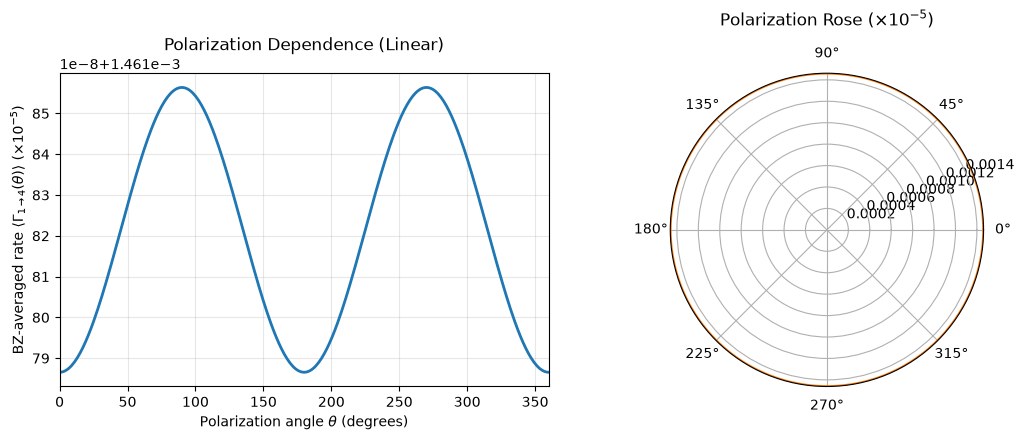

In [54]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import numpy as np
from scipy import constants

# Constants
a = 1.0
t = 1.0
h = constants.hbar
E_o = 1.0
omega = 3 * t / h
pi = np.pi
e = constants.elementary_charge

# Lattice & Reciprocal Vectors
es = np.array([[np.sqrt(3) / 2, 1 / 2], [-np.sqrt(3) / 2, 1 / 2], [0.0, -1.0]])
Deltas = np.array([[-np.sqrt(3) / 2, 3 / 2], [-np.sqrt(3) / 2, -3 / 2], [np.sqrt(3), 0.0]])
bs = (2 * pi / (3 * a)) * np.array([[np.sqrt(3), 1.0], [-np.sqrt(3), 1.0]])


# Vectorized Bloch & Matrix-Element Helpers
def f_i(k_x, k_y, i):
  return np.exp(1j * (k_x * es[i, 0] + k_y * es[i, 1]))


def f_ij(k_x, k_y, i, j):
  return f_i(k_x, k_y, i) - f_i(k_x, k_y, j)


def N_o(k_x, k_y):
  return (8 / 3) * (3 - sum(np.cos(k_x * Deltas[i, 0] + k_y * Deltas[i, 1]) for i in range(3)))


def d_N_o(k_x, k_y, sig):
  return (-8 / 3) * sum(
      Deltas[i, sig] * np.sin(k_x * Deltas[i, 0] + k_y * Deltas[i, 1]) for i in range(3)
  )


def psi_1_t(k_x, k_y):
  return np.array([
      (1 / np.sqrt(3)) * (f_ij(k_x, k_y, 1, 2).conj() - f_ij(k_x, k_y, 2, 0).conj()),
      -1 * f_ij(k_x, k_y, 0, 1).conj(),
      (1 / np.sqrt(3)) * (f_ij(k_x, k_y, 1, 2) - f_ij(k_x, k_y, 2, 0)),
      -1 * f_ij(k_x, k_y, 0, 1),
  ])


def psi_4(k_x, k_y):
  inv_sqrt_No = 1.0 / np.sqrt(N_o(k_x, k_y))
  return inv_sqrt_No * np.array([
      (1 / np.sqrt(3)) * (f_ij(k_x, k_y, 1, 2).conj() - f_ij(k_x, k_y, 2, 0).conj()),
      -1 * f_ij(k_x, k_y, 0, 1).conj(),
      (-1 / np.sqrt(3)) * (f_ij(k_x, k_y, 1, 2) - f_ij(k_x, k_y, 2, 0)),
      1 * f_ij(k_x, k_y, 0, 1),
  ])


def dkx_psi_1_t(k_x, k_y):
  return (1j / 2) * np.array([
      f_i(k_x, k_y, 1).conj() - f_i(k_x, k_y, 0).conj(),
      (f_i(k_x, k_y, 0).conj() + f_i(k_x, k_y, 1).conj()),
      f_i(k_x, k_y, 0) - f_i(k_x, k_y, 1),
      -1*(f_i(k_x, k_y, 0) + f_i(k_x, k_y, 1)),
  ])



def dky_psi_1_t(k_x, k_y):
  return (1j / 2) * np.array([
      (-1 / np.sqrt(3))
      * (f_i(k_x, k_y, 0).conj() + f_i(k_x, k_y, 1).conj() + 4 * f_i(k_x, k_y, 2).conj()),
      f_i(k_x, k_y, 0).conj() - f_i(k_x, k_y, 1).conj(),
      (1 / np.sqrt(3)) * (f_i(k_x, k_y, 0) + f_i(k_x, k_y, 1) + 4 * f_i(k_x, k_y, 2)),
      f_i(k_x, k_y, 1) - f_i(k_x, k_y, 0),
  ])


def delta_lorentzian(x, eta):
  return (1.0 / np.pi) * (eta / (x**2 + eta**2))


def compute_bz_tensor(eta=0.05, N=400):
  # Midpoint grid over primitive reciprocal cell [0, 1)^2
  u = (np.arange(N) + 0.5) / N
  U, V = np.meshgrid(u, u, indexing="ij")
  KX = U * bs[0, 0] + V * bs[1, 0]
  KY = U * bs[0, 1] + V * bs[1, 1]

  No = N_o(KX, KY)
  inv_sqrt_No = 1.0 / np.sqrt(No)
  p4 = psi_4(KX, KY)
  p1_t = psi_1_t(KX, KY)

  dkx_p1 = inv_sqrt_No * (dkx_psi_1_t(KX, KY) - (1 / (2 * No)) * d_N_o(KX, KY, 0) * p1_t)
  dky_p1 = inv_sqrt_No * (dky_psi_1_t(KX, KY) - (1 / (2 * No)) * d_N_o(KX, KY, 1) * p1_t)

  Mx = np.sum(p4.conj() * dkx_p1, axis=0)
  My = np.sum(p4.conj() * dky_p1, axis=0)

  # Note: change 3*t**2 to your detuning (E4 - E1 - h*omega) if evaluating on resonance
  prefactor = (
      (18 * pi * (t**2) / (h**3))
      * ((e * E_o / (2 * omega)) ** 2)
      * delta_lorentzian(3 * t**2, eta)
  )

  I_xx = prefactor * np.mean(np.abs(Mx) ** 2)
  I_yy = prefactor * np.mean(np.abs(My) ** 2)
  I_xy = prefactor * np.mean(np.real(Mx.conj() * My))
  return I_xx, I_yy, I_xy


# 1. Integrate over the BZ once
I_xx, I_yy, I_xy = compute_bz_tensor(eta=0.05, N=400)
print(f"I_xx = {I_xx:.6e}, I_yy = {I_yy:.6e}, I_xy = {I_xy:.6e}")

# 2. Evaluate and plot across all polarization angles theta in [0, 2*pi]
thetas = np.linspace(0, 2 * pi, 360)
avg_gamma_vals = (
    I_xx * np.cos(thetas) ** 2
    + I_yy * np.sin(thetas) ** 2
    + 2 * I_xy * np.cos(thetas) * np.sin(thetas)
)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5), subplot_kw={"projection": None})
ax2.remove()
ax2 = fig.add_subplot(1, 2, 2, projection="polar")

# Cartesian plot
ax1.plot(np.degrees(thetas), avg_gamma_vals * 1e5, lw=2, color="tab:blue")
ax1.set_xlabel(r"Polarization angle $\theta$ (degrees)")
ax1.set_ylabel(r"BZ-averaged rate $\langle\Gamma_{1\to4}(\theta)\rangle$ ($\times 10^{-5}$)")
ax1.set_title("Polarization Dependence (Linear)")
ax1.set_xlim(0, 360)
ax1.grid(True, alpha=0.3)

# Polar plot
ax2.plot(thetas, avg_gamma_vals * 1e5, lw=2, color="tab:orange")
ax2.set_title(r"Polarization Rose ($\times 10^{-5}$)", pad=15)

plt.tight_layout()
plt.show()
